# 14조 · 중도탈락 고위험 학과 예측
## 1. 수집

In [3]:
import pandas as pd, numpy as np

RANDOM_STATE = 42
MIN_ENROLL = 30          # 민감도: 10, 50
FILE = '교육부_대학알리미_중도탈락_학생_현황__대학_학과별_20260831.csv'
REASONS = ['미등록','미복학','자퇴','학사경고','학생활동','유급제적','재학연한초과','기타']
KEY = ['공시연도','학교코드','학과코드']

collect_record = {
    '데이터명': '교육부_대학알리미_중도탈락 학생 현황_대학_학과별',
    'URL': 'https://www.data.go.kr/data/15164570/fileData.do',
    '제공기관': '교육부', '이용조건': '공공누리 제1유형(출처 표시)',
    '파일명 날짜': '2026-08-31', '포털 등록일': '2026-09-10', '다운로드일': '2026-11-08',
}

raw = pd.read_csv(FILE, encoding='utf-8-sig', low_memory=False)
assert raw.shape == (56340, 32), raw.shape
df = raw.copy()

In [4]:
clean_log = []
def log(step, n, reason, impact):
    clean_log.append({'처리': step, '건수': int(n), '근거': reason, '영향': impact})
    print(f'[{step}] {n:,}건')

## 2. 정제

In [5]:
assert df.duplicated().sum() == 0
assert df.duplicated(KEY).sum() == 0
log('완전 중복·키 중복 확인', 0, '(공시연도, 학교코드, 학과코드) 기준', '처리 없음')

[완전 중복·키 중복 확인] 0건


In [6]:
print(df.groupby('공시연도')['계'].apply(lambda s: s.isna().sum()).to_dict())
df['f_재적0'] = df['재적학생'].eq(0)
print(pd.crosstab(df['f_재적0'], df['중도탈락학생비율'].isna(), margins=True))
log('재적 0 표시', df['f_재적0'].sum(),
    '분모 0으로 비율 정의 불가. 그중 1,697행은 공시 비율이 0.0으로 기록', '재계산 비율에서 결측 처리')

{2023: 46, 2024: 1795, 2025: 1770, 2026: 1958}
중도탈락학생비율  False  True    All
f_재적0                       
False     48271  5569  53840
True       1697   803   2500
All       49968  6372  56340
[재적 0 표시] 2,500건


In [7]:
df['비율_재계산'] = np.where(df['f_재적0'], np.nan, df['계'] / df['재적학생'] * 100)
diff = (df['비율_재계산'] - df['중도탈락학생비율']).abs()
for tol in [0.005, 0.01, 0.1]:
    print(f'차이 > {tol}: {(diff > tol).sum()}건')

df['f_100초과'] = df['비율_재계산'] > 100
print(df['f_100초과'].sum(), round((df.loc[df['f_100초과'], '재적학생'] <= 5).mean(), 3))
log('비율 100% 초과 표시', df['f_100초과'].sum(), '87%가 재적 5명 이하', '최소 재적 기준으로 통제')

차이 > 0.005: 190건
차이 > 0.01: 0건
차이 > 0.1: 0건
172 0.872
[비율 100% 초과 표시] 172건


In [8]:
ok = df['계'].notna()
assert (df.loc[ok, REASONS].sum(axis=1) == df.loc[ok, '계']).all()
log('사유 합 = 계 확인', 0, '불일치 0행', '사유 구성비 변수로 사용 가능')

[사유 합 = 계 확인] 0건


In [9]:
df['f_기준연도동일'] = df['기준연도'].eq(df['공시연도'])
print(df['f_기준연도동일'].sum())
log('기준연도=공시연도 표시', df['f_기준연도동일'].sum(),
    '대부분은 기준연도=공시연도-1. 원인 미확인', '유지·표시, 민감도에서 제외 버전 비교')

519
[기준연도=공시연도 표시] 519건


## 분석 범위
- 대상: 학교종류=대학교, 주야간구분=주간, 학과특성=일반과정 (50,544행)
- 이유: 의사결정자(한국외대)와 같은 유형으로 비교 대상 한정
- 제외: 5,796행 (유형 목록은 계획서 V장 한계 참고)

In [10]:
scope = (df['학교종류'].eq('대학교')
         & df['주야간구분'].eq('주간')
         & df['학과특성'].eq('일반과정'))
log('분석 범위: 대학교·주간·일반과정', (~scope).sum(),
    '의사결정자(한국외대)와 같은 유형으로 비교 대상 한정', f'남은 행 {scope.sum():,}')
df = df[scope].copy()
assert len(df) == 50544

for c in ['설립유형', '소재지유형', '표준분류_대계열']:
    print(c, df.groupby(c)['계'].apply(lambda s: round(s.isna().mean() * 100, 1)).to_dict())

[분석 범위: 대학교·주간·일반과정] 5,796건
설립유형 {'국공립': 9.4, '사립': 9.8}
소재지유형 {'비수도권': 9.9, '수도권': 9.2}
표준분류_대계열 {'공학계열': 10.3, '광역계열': 0.0, '예체능계열': 9.6, '의학계열': 40.5, '인문사회계열': 9.2, '자연과학계열': 9.3}


In [11]:
assert len(df) == 50544   # 범위 필터가 빠지면 여기서 멈춤
prev = df[KEY + ['비율_재계산', '재적학생', '계'] + REASONS + ['f_재적0']].copy()
prev['공시연도'] += 1
prev = prev.rename(columns={c: c + '_전년' for c in prev.columns if c not in KEY})
pairs = df.merge(prev, on=KEY, how='inner')
assert len(pairs) == 32302
print(pairs['공시연도'].value_counts().sort_index().to_dict())
log('전년→당해 쌍 구성', len(pairs), '같은 학교코드·학과코드가 연속 공시연도에 존재', '필터 적용 전')

{2024: 10744, 2025: 10708, 2026: 10850}
[전년→당해 쌍 구성] 32,302건


In [12]:
steps = [
    ('전년 재적 0 제외', lambda p: p['f_재적0_전년']),
    ('당해 재적 0 제외', lambda p: p['f_재적0']),
    ('전년·당해 비율 결측 제외', lambda p: p['비율_재계산_전년'].isna() | p['비율_재계산'].isna()),
    (f'전년 재적 {MIN_ENROLL}명 미만 제외', lambda p: p['재적학생_전년'] < MIN_ENROLL),
    ('폐교·신설 제외', lambda p: p['학교상태'].isin(['폐교', '신설'])),
]
for name, rule in steps:
    mask = rule(pairs)
    n = mask.sum()
    pairs = pairs[~mask].copy()
    log(name, n, '계획서 III장 사전 고정 기준', f'남은 쌍 {len(pairs):,}')
assert len(pairs) == 23101

[전년 재적 0 제외] 791건
[당해 재적 0 제외] 230건
[전년·당해 비율 결측 제외] 5,143건
[전년 재적 30명 미만 제외] 2,765건
[폐교·신설 제외] 272건


## 3. 분석

In [13]:
TRAIN_YEARS, TEST_YEAR = [2024, 2025], 2026
train_mask = pairs['공시연도'].isin(TRAIN_YEARS)

CUT = pairs.loc[train_mask, '비율_재계산'].quantile(0.75)   # 학습 데이터로만
pairs['고위험'] = (pairs['비율_재계산'] >= CUT).astype(int)
pairs['고위험_전년'] = (pairs['비율_재계산_전년'] >= CUT).astype(int)
print(f'컷: {CUT:.2f}%')
print(pairs.loc[train_mask, '고위험'].agg(['count', 'sum', 'mean']))
log('고위험 라벨 생성', pairs['고위험'].sum(),
    f'학습(2024·2025) 75 백분위 컷 {CUT:.2f}%를 전 기간에 동일 적용', '분류 대상 y')
assert train_mask.sum() == 15608 and pairs.loc[train_mask, '고위험'].sum() == 3904

컷: 7.91%
count    15608.000000
sum       3904.000000
mean         0.250128
Name: 고위험, dtype: float64
[고위험 라벨 생성] 5,666건


### H2 사유: 자퇴·미등록·미복학 비중

In [15]:
H2_REASONS = ['자퇴', '미등록', '미복학']
valid = df[df['계'].notna()]          # 범위 내, 계가 있는 행
def share(g):
    return g[H2_REASONS].sum().sum() / g['계'].sum() * 100

print(f'전체: {share(valid):.1f}%')
print('연도별:', valid.groupby('공시연도').apply(share).round(1).to_dict())
print('계열별:', valid.groupby('표준분류_대계열').apply(share).round(1).to_dict())

전체: 97.0%
연도별: {2023: 97.0, 2024: 97.0, 2025: 97.0, 2026: 96.9}
계열별: {'공학계열': 96.8, '광역계열': 97.0, '예체능계열': 96.7, '의학계열': 74.7, '인문사회계열': 97.0, '자연과학계열': 97.6}


/tmp/ipykernel_1365/218253577.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print('연도별:', valid.groupby('공시연도').apply(share).round(1).to_dict())
/tmp/ipykernel_1365/218253577.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print('계열별:', valid.groupby('표준분류_대계열').apply(share).round(1).to_dict())


### 기준선과 예측 모델 (H3), 테스트 = 공시 2026

In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix

def report(name, y_true, y_pred, score=None):
    print(name, '혼동행렬 [[TN, FP], [FN, TP]]:', confusion_matrix(y_true, y_pred).tolist())
    return {'방법': name, '선택 학과 수': int(y_pred.sum()),
            '정확도': accuracy_score(y_true, y_pred),
            '정밀도': precision_score(y_true, y_pred, zero_division=0),
            '재현율': recall_score(y_true, y_pred),
            'AUC': roc_auc_score(y_true, score) if score is not None else np.nan}

test = pairs[pairs['공시연도'] == TEST_YEAR]
assert len(test) == 7493
results = []
results.append(report('기준선① 전원 0', test['고위험'], np.zeros(len(test), dtype=int)))
results.append(report('기준선② 전년 고위험', test['고위험'], test['고위험_전년'].values,
                      test['비율_재계산_전년'].values))
K = int(test['고위험_전년'].sum())   # 기준선②가 고른 학과 수 → 모델도 같은 k로 비교
print('K =', K)

기준선① 전원 0 혼동행렬 [[TN, FP], [FN, TP]]: [[5731, 0], [1762, 0]]
기준선② 전년 고위험 혼동행렬 [[TN, FP], [FN, TP]]: [[4929, 802], [633, 1129]]
K = 1931


In [17]:
for r in REASONS:
    pairs[f'{r}_구성비_전년'] = np.where(pairs['계_전년'] > 0,
                                     pairs[f'{r}_전년'] / pairs['계_전년'], 0)
pairs['log재적_전년'] = np.log(pairs['재적학생_전년'])

NUM = ['비율_재계산_전년', 'log재적_전년'] + [f'{r}_구성비_전년' for r in REASONS if r != '기타']
CAT = ['설립유형', '소재지유형', '표준분류_대계열']
assert pairs[NUM + CAT].isna().sum().sum() == 0
print('전년 탈락 0명 쌍:', (pairs['계_전년'] == 0).sum())

전년 탈락 0명 쌍: 474


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

train = pairs[pairs['공시연도'].isin(TRAIN_YEARS)]
test = pairs[pairs['공시연도'] == TEST_YEAR]

model = Pipeline([
    ('prep', ColumnTransformer([
        ('num', StandardScaler(), NUM),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), CAT)])),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
model.fit(train[NUM + CAT], train['고위험'])
prob = model.predict_proba(test[NUM + CAT])[:, 1]

results.append(report('모델 임계값 0.5', test['고위험'], (prob >= 0.5).astype(int), prob))
topk = np.zeros(len(test), dtype=int)
topk[np.argsort(-prob)[:K]] = 1
results.append(report(f'모델 상위 k={K}', test['고위험'], topk, prob))

res = pd.DataFrame(results).round(3)
res

모델 임계값 0.5 혼동행렬 [[TN, FP], [FN, TP]]: [[5304, 427], [892, 870]]
모델 상위 k=1931 혼동행렬 [[TN, FP], [FN, TP]]: [[4979, 752], [583, 1179]]


,방법,선택 학과 수,정확도,정밀도,재현율,AUC
0,기준선① 전원 0,0,0.765,0.000,0.000,NaN
1,기준선② 전년 고위험,1931,0.808,0.585,0.641,0.829
2,모델 임계값 0.5,1297,0.824,0.671,0.494,0.868
3,모델 상위 k=1931,1931,0.822,0.611,0.669,0.868


### H1 구조: 비수도권·사립·소규모의 오즈비 (학교 단위 군집 표준오차)

In [19]:
import statsmodels.api as sm

h1 = pairs[pairs['공시연도'].isin(TRAIN_YEARS) & ~pairs['표준분류_대계열'].eq('의학계열')].copy()
SMALL_CUT = pairs.loc[pairs['공시연도'].isin(TRAIN_YEARS), '재적학생_전년'].quantile(0.25)

X = pd.DataFrame({
    '비수도권': (h1['소재지유형'] == '비수도권').astype(float),
    '사립': (h1['설립유형'] == '사립').astype(float),
    '소규모': (h1['재적학생_전년'] <= SMALL_CUT).astype(float),
    '전년비율': h1['비율_재계산_전년'],
})
X = pd.concat([X, pd.get_dummies(h1['표준분류_대계열'], prefix='계열', drop_first=True).astype(float)], axis=1)
X = sm.add_constant(X)

h1_fit = sm.Logit(h1['고위험'], X).fit(disp=0, cov_type='cluster',
                                       cov_kwds={'groups': h1['학교코드']})
ci = np.exp(h1_fit.conf_int())
h1_table = pd.DataFrame({'오즈비': np.exp(h1_fit.params), '95% 하한': ci[0], '95% 상한': ci[1],
                         'p값': h1_fit.pvalues}).round(3)
print(f'소규모 기준: 전년 재적 ≤ {SMALL_CUT:.0f}명, 분석 쌍 {len(h1):,}, 학교 {h1["학교코드"].nunique()}개')
h1_table

소규모 기준: 전년 재적 ≤ 94명, 분석 쌍 15,562, 학교 205개


,오즈비,95% 하한,95% 상한,p값
const,0.015,0.011,0.022,0.000
비수도권,2.330,1.848,2.939,0.000
사립,2.240,1.699,2.954,0.000
소규모,2.091,1.845,2.370,0.000
전년비율,1.280,1.243,1.318,0.000
계열_예체능계열,1.170,0.985,1.389,0.073
계열_인문사회계열,1.020,0.900,1.157,0.753
계열_자연과학계열,0.835,0.711,0.980,0.028


In [20]:
def topk_precision(p, y, k):
    pick = np.zeros(len(p), dtype=int); pick[np.argsort(-p)[:k]] = 1
    return precision_score(y, pick)

only_prev = LogisticRegression(max_iter=1000).fit(train[['비율_재계산_전년']], train['고위험'])
p_only = only_prev.predict_proba(test[['비율_재계산_전년']])[:, 1]

NUM_wo = [c for c in NUM if c != '비율_재계산_전년']
wo_prev = Pipeline([('prep', ColumnTransformer([('num', StandardScaler(), NUM_wo),
              ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), CAT)])),
              ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
wo_prev.fit(train[NUM_wo + CAT], train['고위험'])
p_wo = wo_prev.predict_proba(test[NUM_wo + CAT])[:, 1]

pd.DataFrame({
    '모델': ['전년 비율 하나만', '전년 비율 빼고 나머지 전부', '전체 모델'],
    f'상위 k={K} 정밀도': [topk_precision(p_only, test['고위험'], K),
                         topk_precision(p_wo, test['고위험'], K),
                         topk_precision(prob, test['고위험'], K)],
    'AUC': [roc_auc_score(test['고위험'], p_only), roc_auc_score(test['고위험'], p_wo),
            roc_auc_score(test['고위험'], prob)]}).round(3)

,모델,상위 k=1931 정밀도,AUC
0,전년 비율 하나만,0.585,0.829
1,전년 비율 빼고 나머지 전부,0.528,0.797
2,전체 모델,0.611,0.868


### 민감도: 최소 재적, 기준연도 동일행, 임계값

In [21]:
def run_setting(min_enroll=30, drop_basis_same=False):
    d = df[~df['f_기준연도동일']] if drop_basis_same else df
    pv = d[KEY + ['비율_재계산', '재적학생', '계'] + REASONS + ['f_재적0']].copy()
    pv['공시연도'] += 1
    pv = pv.rename(columns={c: c + '_전년' for c in pv.columns if c not in KEY})
    p = d.merge(pv, on=KEY, how='inner')
    p = p[~p['f_재적0_전년'] & ~p['f_재적0']]
    p = p[p['비율_재계산_전년'].notna() & p['비율_재계산'].notna()]
    p = p[(p['재적학생_전년'] >= min_enroll) & ~p['학교상태'].isin(['폐교', '신설'])].copy()
    tr = p['공시연도'].isin(TRAIN_YEARS); te = p['공시연도'].eq(TEST_YEAR)
    cut = p.loc[tr, '비율_재계산'].quantile(0.75)
    p['고위험'] = (p['비율_재계산'] >= cut).astype(int)
    p['고위험_전년'] = (p['비율_재계산_전년'] >= cut).astype(int)
    for r in REASONS:
        p[f'{r}_구성비_전년'] = np.where(p['계_전년'] > 0, p[f'{r}_전년'] / p['계_전년'], 0)
    p['log재적_전년'] = np.log(p['재적학생_전년'])
    m = Pipeline([('prep', ColumnTransformer([('num', StandardScaler(), NUM),
                 ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), CAT)])),
                 ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
    m.fit(p.loc[tr, NUM + CAT], p.loc[tr, '고위험'])
    t = p[te]; pr = m.predict_proba(t[NUM + CAT])[:, 1]
    k = int(t['고위험_전년'].sum())
    base = precision_score(t['고위험'], t['고위험_전년'])
    mod = topk_precision(pr, t['고위험'], k)
    return {'최소 재적': min_enroll, '기준연도 동일행 제외': drop_basis_same,
            '컷(%)': round(cut, 2), '테스트 쌍': len(t), 'k': k,
            '기준선② 정밀도': round(base, 3), '모델 정밀도': round(mod, 3),
            '개선(%p)': round((mod - base) * 100, 1)}

sens = pd.DataFrame([run_setting(10), run_setting(30), run_setting(50), run_setting(30, True)])
sens

,최소 재적,기준연도 동일행 제외,컷(%),테스트 쌍,k,기준선② 정밀도,모델 정밀도,개선(%p)
0,10,False,8.70,8178,2077,0.592,0.628,3.6
1,30,False,7.91,7493,1931,0.585,0.611,2.6
2,50,False,7.49,6824,1727,0.586,0.603,1.7
3,30,True,7.91,7493,1931,0.585,0.611,2.6


In [22]:
rows = []
for th in [0.3, 0.4, 0.5, 0.6]:
    pick = (prob >= th).astype(int)
    rows.append({'임계값': th, '선택 학과 수': int(pick.sum()),
                 '정밀도': precision_score(test['고위험'], pick),
                 '재현율': recall_score(test['고위험'], pick)})
pd.DataFrame(rows).round(3)

,임계값,선택 학과 수,정밀도,재현율
0,0.3,2311,0.572,0.750
1,0.4,1724,0.634,0.620
2,0.5,1297,0.671,0.494
3,0.6,968,0.713,0.392


### 시각화 3종

In [23]:
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rc('font', family='NanumGothic'); plt.rc('axes', unicode_minus=False)

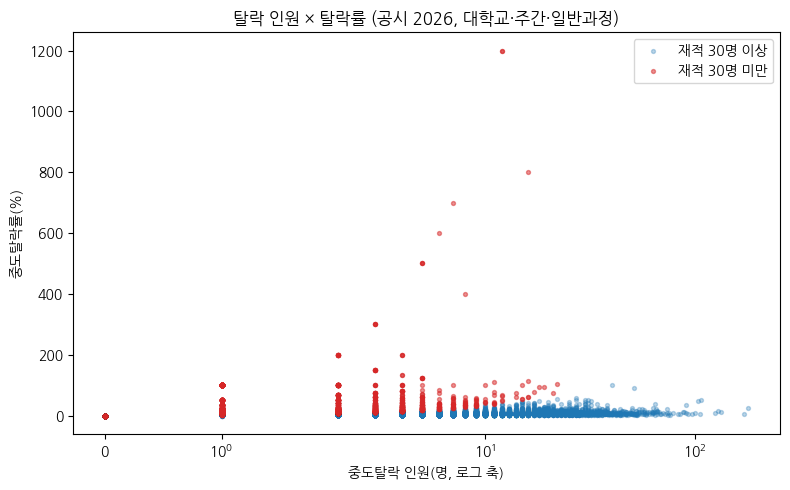

In [24]:
v = df[(df['공시연도'] == TEST_YEAR) & df['비율_재계산'].notna()]
small = v['재적학생'] < MIN_ENROLL
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(v.loc[~small, '계'], v.loc[~small, '비율_재계산'], s=8, alpha=0.3, label=f'재적 {MIN_ENROLL}명 이상')
ax.scatter(v.loc[small, '계'], v.loc[small, '비율_재계산'], s=8, alpha=0.5, color='tab:red', label=f'재적 {MIN_ENROLL}명 미만')
ax.set_xscale('symlog'); ax.set_xlabel('중도탈락 인원(명, 로그 축)'); ax.set_ylabel('중도탈락률(%)')
ax.set_title('탈락 인원 × 탈락률 (공시 2026, 대학교·주간·일반과정)'); ax.legend()
fig.tight_layout(); fig.savefig('차트1_산점도.png', dpi=200); plt.show()

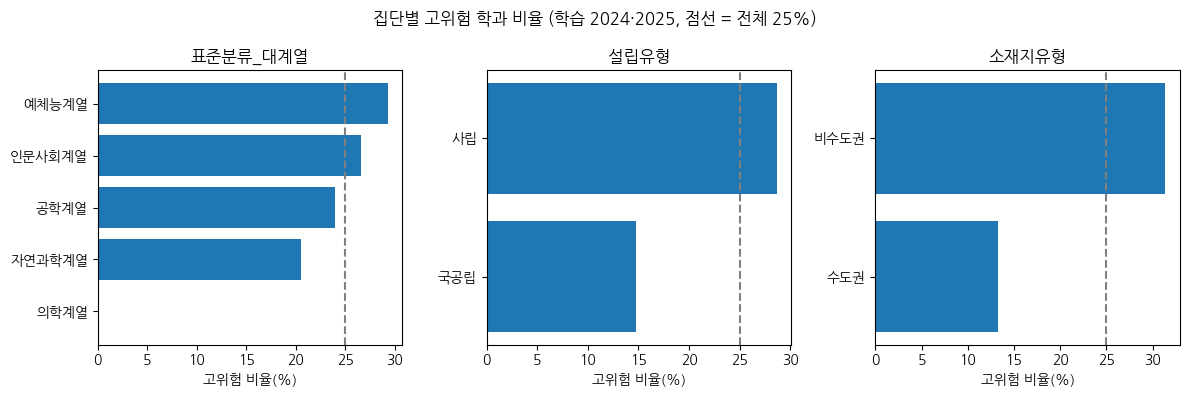

In [25]:
tr = pairs[pairs['공시연도'].isin(TRAIN_YEARS)]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ['표준분류_대계열', '설립유형', '소재지유형']):
    s = tr.groupby(col)['고위험'].mean().sort_values() * 100
    ax.barh(s.index, s.values); ax.axvline(25, ls='--', color='gray')
    ax.set_title(col); ax.set_xlabel('고위험 비율(%)')
fig.suptitle('집단별 고위험 학과 비율 (학습 2024·2025, 점선 = 전체 25%)'); fig.tight_layout()
fig.savefig('차트2_집단별.png', dpi=200); plt.show()

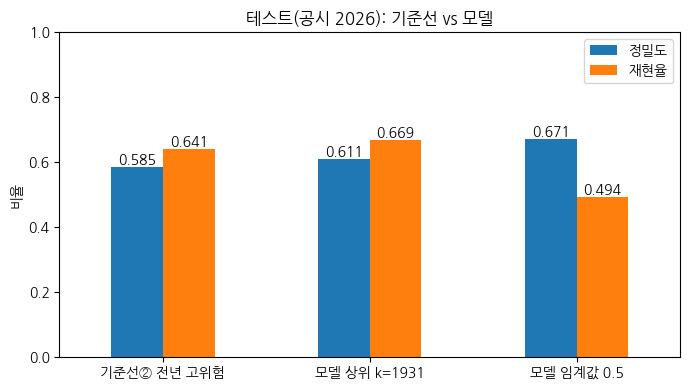

In [26]:
r = res.set_index('방법').loc[['기준선② 전년 고위험', f'모델 상위 k={K}', '모델 임계값 0.5'], ['정밀도', '재현율']]
ax = r.plot.bar(figsize=(7, 4), rot=0); ax.set_ylim(0, 1); ax.set_ylabel('비율'); ax.set_xlabel('')
ax.set_title('테스트(공시 2026): 기준선 vs 모델')
for c in ax.containers: ax.bar_label(c, fmt='%.3f')
plt.tight_layout(); plt.savefig('차트3_모델비교.png', dpi=200); plt.show()

### H4 한국외대: 소규모 어문군 vs 교내 기타 학과 vs 타교 동일 소계열 (공시 2024~2026)

In [27]:
H4_SUB = ['기타유럽어・문학', '기타아시아어・문학']   # 가운데 점은 데이터 그대로 복사한 문자
h4 = df[df['공시연도'].isin([2024, 2025, 2026]) & df['계'].notna() & ~df['f_재적0']].copy()
is_hufs = h4['학교명'].eq('한국외국어대학교')       # contains 쓰면 사이버한국외대가 섞임
is_sub = h4['표준분류_소계열'].isin(H4_SUB)
groups = {'A 한국외대 어문군': h4[is_hufs & is_sub],
          'B 한국외대 기타 학과': h4[is_hufs & ~is_sub],
          'C 타교 동일 소계열': h4[~is_hufs & is_sub]}
def rate(g): return g['계'].sum() / g['재적학생'].sum() * 100

print(pd.DataFrame({k: {'행': len(g), '학교 수': g['학교코드'].nunique(),
                        '학과 수': g[['학교코드','학과코드']].drop_duplicates().shape[0],
                        '합산 탈락률(%)': round(rate(g), 2)} for k, g in groups.items()}).T)

rng = np.random.default_rng(RANDOM_STATE)
def boot(g, n=2000):
    units = [u for _, u in g.groupby(['학교코드', '학과코드'])]   # 학과 단위로 재표집
    return np.array([rate(pd.concat([units[i] for i in rng.integers(0, len(units), len(units))]))
                     for _ in range(n)])
bA, bB, bC = (boot(g) for g in groups.values())
for name, other in [('A − B', bB), ('A − C', bC)]:
    lo, hi = np.percentile(bA - other, [2.5, 97.5])
    print(f'{name}: 95% 구간 [{lo:.2f}, {hi:.2f}]%p')

                  행  학교 수   학과 수  합산 탈락률(%)
A 한국외대 어문군     68.0   1.0   32.0       3.48
B 한국외대 기타 학과  315.0   1.0  142.0       4.73
C 타교 동일 소계열    93.0   8.0   43.0       6.98
A − B: 95% 구간 [-1.91, -0.56]%p
A − C: 95% 구간 [-5.49, -2.31]%p


In [14]:
log_df = pd.DataFrame(clean_log)
log_df.to_csv('정제로그.csv', index=False, encoding='utf-8-sig')
log_df

,처리,건수,근거,영향
0,완전 중복·키 중복 확인,0,"(공시연도, 학교코드, 학과코드) 기준",처리 없음
1,재적 0 표시,2500,"분모 0으로 비율 정의 불가. 그중 1,697행은 공시 비율이 0.0으로 기록",재계산 비율에서 결측 처리
2,비율 100% 초과 표시,172,87%가 재적 5명 이하,최소 재적 기준으로 통제
3,사유 합 = 계 확인,0,불일치 0행,사유 구성비 변수로 사용 가능
4,기준연도=공시연도 표시,519,대부분은 기준연도=공시연도-1. 원인 미확인,"유지·표시, 민감도에서 제외 버전 비교"
5,분석 범위: 대학교·주간·일반과정,5796,의사결정자(한국외대)와 같은 유형으로 비교 대상 한정,"남은 행 50,544"
6,전년→당해 쌍 구성,32302,같은 학교코드·학과코드가 연속 공시연도에 존재,필터 적용 전
7,전년 재적 0 제외,791,계획서 III장 사전 고정 기준,"남은 쌍 31,511"
8,당해 재적 0 제외,230,계획서 III장 사전 고정 기준,"남은 쌍 31,281"
9,전년·당해 비율 결측 제외,5143,계획서 III장 사전 고정 기준,"남은 쌍 26,138"
